## Build basic chat bot

In [ ]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

In [ ]:
class State(TypedDict):
    messages : Annotated[list, add_messages]
 
graph_builder = StateGraph(State)
graph_builder


In [ ]:
from dotenv import load_dotenv
load_dotenv()

In [ ]:
from langchain_groq import ChatGroq

In [ ]:
llm = ChatGroq(model = "openai/gpt-oss-120b")

In [ ]:
def chatBot(state:State):
    return{"messages":[llm.invoke(state["messages"])]}

In [ ]:
graph_builder = StateGraph(State)
graph_builder.add_node("chatbot",chatBot)
graph_builder.add_edge(START,"chatbot")
graph_builder.add_edge("chatbot", END)

In [ ]:
graph = graph_builder.compile()

In [ ]:
from IPython.display import Image, display

In [ ]:
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [ ]:
res = graph.invoke({"messages":"who's the pm of india?"})
print(res)

## Chatbot with tool

In [ ]:
from langchain_tavily import TavilySearch

In [ ]:
tool = TavilySearch(max_results = 2)
res = tool.invoke("what is langgraph?")
print(res)

## custom function

In [ ]:
def multiply(a:int, b:int)->int:
    """
    this function returns multiplication of a and b

    Args:
    a (int) : first int
    b (int) : second int

    Return:
    output int
    """
    return a * b

In [ ]:
tools = [tool,multiply]

In [ ]:
llm_with_tool = llm.bind_tools(tools)

In [ ]:
llm_with_tool

## Stategraph

In [ ]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

In [ ]:
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition


def tool_calling_llm(state:State):
    return{"messages":[llm_with_tool.invoke(state["messages"])]}

# build graph, nodes
builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

# build edges

builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm", tools_condition)
builder.add_edge("tools", END)

final_graph = builder.compile()

from IPython.display import Image, display

try:
   display(Image(final_graph.get_graph().draw_mermaid_png()))
except Exception:
    pass 

In [ ]:
res= final_graph.invoke({"messages":"what is recent ai news?"})
print(res["messages"][-1].text)

In [ ]:
res= final_graph.invoke({"messages":"what is 2 * 3"})
print(res["messages"][-1].text)

In [ ]:
res= final_graph.invoke({"messages":"what is 2 * 3 and what is the recent ai news?"})
print(res["messages"][-1].text)

## ReAct agent architecture 

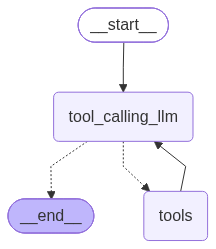

In [146]:
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

def tool_calling_llm(state:State):
    return{"messages":[llm_with_tool.invoke(state["messages"])]}

# build graph, nodes
builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

# build edges

builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm", tools_condition)
builder.add_edge("tools", "tool_calling_llm")

final1_graph = builder.compile()

from IPython.display import Image, display

try:
   display(Image(final1_graph.get_graph().draw_mermaid_png()))
except Exception:
    pass 

In [147]:
res = final1_graph.invoke({"messages":"what is 2 *3 and what is recent ai news?"})

In [148]:
print(res["messages"][-1].text)

**2 × 3 = 6**

---

## Recent AI News (Late September – Early October 2026)

| Source | Key Highlights |
|--------|-----------------|
| **Medium – “AI NEWS: Week of 28 September to 4 October 2026”** | • **OpenAI** unveiled **Dots**, a new generation of personal AI agents that can keep working autonomously after the user steps away. Each Dot has its own cloud‑based compute environment, can be assigned specific goals, and can connect (with permission) to **4,000+ apps and services** to search, track projects, and act without waiting for a new prompt. <br>• **NVIDIA** announced a financing program that treats its AI GPUs and compute resources as **collateral**, enabling developers to borrow up to **$500 billion** to access NVIDIA’s hardware. The move aims to turn “compute” into a tradable infrastructure asset, similar to aircraft financing models. |
| **TechNet – “AI in Action | October 2026”** | • TechNet urged **NIST** to keep a **flexible, risk‑based approach** for AI evaluation standa

In [149]:
res = final1_graph.invoke({"messages":"hello, my name is pooja"})
print(res["messages"][-1].text)

Hello Pooja! Nice to meet you. How can I help you today?


In [150]:
res = final1_graph.invoke({"messages":"what is my name?"})
print(res["messages"][-1].text)

I don’t have any information about your name. If you’d like me to address you a certain way, just let me know!


## Adding memory

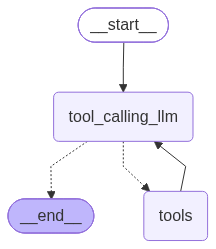

In [151]:
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import InMemorySaver

memory = InMemorySaver()

def tool_calling_llm(state:State):
    return{"messages":[llm_with_tool.invoke(state["messages"])]}

# build graph, nodes
builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

# build edges

builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm", tools_condition)
builder.add_edge("tools", "tool_calling_llm")

final2_graph = builder.compile(checkpointer = memory)

from IPython.display import Image, display

try:
   display(Image(final2_graph.get_graph().draw_mermaid_png()))
except Exception:
    pass 



In [152]:
config = {"configurable":{"thread_id":"1"}}
res = final2_graph.invoke({"messages":"My name is pooja"}, config = config)
res["messages"][-1].text

'Nice to meet you, Pooja! How can I assist you today?'

In [153]:
res = final2_graph.invoke({"messages":"whats my name?"}, config= config)
res["messages"][-1].text

'Your name is Pooja.'

## Streaming

In [154]:
from langgraph.checkpoint.memory import InMemorySaver
memory = InMemorySaver()

In [155]:
def superbot(state:State):
    return{"messages":llm.invoke(state["messages"])}

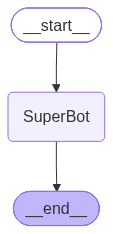

In [163]:
graph = StateGraph(State)
graph.add_node("SuperBot",superbot)

graph.add_edge(START,"SuperBot")
graph.add_edge("SuperBot", END)

graph3 = graph.compile(checkpointer = memory)

from IPython.display import Image, display

try:
   display(Image(graph3.get_graph().draw_mermaid_png()))
except Exception:
    pass 




In [164]:
config = {"configurable":{"thread_id":"1"}}
res = graph3.invoke({"messages":"hey, i'm pooja i love listening songs"}, config = config)
print(res["messages"][-1].text)

Hey Pooja! 🎧 It’s great to meet a fellow music lover.  

**What kind of songs are you in the mood for today?**  

| Mood / Situation | Quick Playlist Picks |
|------------------|----------------------|
| **Feel‑good Bollywood** | “Nashe Si Chadh Gayi” – *Befikre*  •  “Kar Gayi Chull” – *Kapoor & Sons*  •  “Dil Dhadakne Do” – *Zindagi Na Milegi Dobara* |
| **Chill/Study Lo‑fi** | “Coffee Breath” – Birocratic  •  “Snowfall” – Mounika.  •  “Dreams” – Joakim Karud |
| **Pop‑catchy** | “Levitating” – Dua Lipa  •  “Blinding Lights” – The Weeknd  •  “Bad Guy” – Billie Eilish |
| **Indie/Alternative** | “Cold Little Heart” – Mitski  •  “Nadaan Parindey” – Amit Trivedi (Indie‑flavoured Bollywood)  •  “Lost in Yesterday” – Tame Impala |
| **Classic Rock** | “Dream On” – Aerosmith  •  “Hotel California” – Eagles  •  “Don’t Stop Me Now” – Queen |
| **Relaxing Classical** | “Clair de Lune” – Debussy  •  “Gymnopédie No. 1” – Satie  •  “Moonlight Sonata (1st mvt)” – Beethoven |

If any of those catch

## Streaming

Streaming
Methods: .stream() and astream()

These methods are sync and async methods for streaming back results.
Additional parameters in streaming modes for graph state

values : This streams the full state of the graph after each node is called.
updates : This streams updates to the state of the graph after each node is called.

In [177]:
config = {"configurable":{"thread_id":"2"}}
for chunk in graph3.stream({"messages":"Hi my name is pooja and i love listening to music"},config , steam_mode = "updates"):
    print(chunk)

{'SuperBot': {'messages': AIMessage(content='Hi Pooja! 🎧 It’s great to meet a fellow music lover. What kind of music are you into right now? Do you have any favorite artists, genres, or playlists you keep on repeat? Let me know, and I can suggest new tracks, build a custom playlist, or share some fresh releases that match your taste!', additional_kwargs={'reasoning_content': "The user keeps repeating the same phrase. The assistant should respond appropriately, maybe ask a question, or provide some suggestions. There's no policy violation. We can respond politely, ask what kind of music they like. Possibly the user is testing. Provide a helpful response.\n\nWe should not repeat the same content endlessly. Provide a concise answer."}, response_metadata={'token_usage': {'completion_tokens': 146, 'prompt_tokens': 1283, 'total_tokens': 1429, 'completion_time': 0.308929435, 'completion_tokens_details': {'reasoning_tokens': 68}, 'prompt_time': 0.059894236, 'prompt_tokens_details': None, 'queu

In [178]:
for chunk in graph3.stream({"messages":"Hi my name is pooja and i love listening to music"},config , steam_mode = "values"):
    print(chunk)

{'SuperBot': {'messages': AIMessage(content='Hi Pooja! 🎶 It’s wonderful to meet another music enthusiast.  \n\nWhat’s been on your rotation lately? Do you have a go‑to genre, a favorite artist, or a playlist you can’t stop listening to? Let me know what you’re in the mood for—whether it’s chill vibes, workout beats, road‑trip anthems, or something totally new—and I can share recommendations, fresh releases, or even help you build a custom playlist!', additional_kwargs={'reasoning_content': 'The user keeps repeating the same message. Possibly they want a response acknowledging. We should respond politely, perhaps ask a question to engage. Avoid redundancy. Provide suggestions. Ensure not to violate policy. Just a friendly response.'}, response_metadata={'token_usage': {'completion_tokens': 151, 'prompt_tokens': 1374, 'total_tokens': 1525, 'completion_time': 0.316029705, 'completion_tokens_details': {'reasoning_tokens': 45}, 'prompt_time': 0.04753698, 'prompt_tokens_details': {'cached_to

In [179]:
config = {"configurable":{"thread_id":"3"}}
for chunk in graph3.stream({"messages":"Hi my name is pooja and i love listening to music"},config , steam_mode = "updates"):
    print(chunk)

{'SuperBot': {'messages': AIMessage(content='Hey Pooja! 👋 Great to meet you. Music is such a wonderful passion—there’s always a perfect track for every mood.\n\nWhat kind of music do you enjoy most? 🎧  \n- Pop, rock, indie, hip‑hop, classical, jazz, EDM, folk, K‑pop… the list goes on!  \n- Do you have any favorite artists or songs that you keep on repeat?  \n- Are you into discovering new releases, building playlists, or maybe even playing an instrument?\n\nIf you’d like, I can suggest some fresh tunes, hidden‑gem playlists, or even share a fun fact about a genre you love. Just let me know what you’re in the mood for! 🎶', additional_kwargs={'reasoning_content': 'We need to respond. The user says "Hi my name is pooja and i love listening to music". Likely a greeting and sharing interest. We can respond with a friendly reply, ask about favorite genres, maybe recommend music. Keep it friendly.'}, response_metadata={'token_usage': {'completion_tokens': 208, 'prompt_tokens': 83, 'total_toke

In [180]:
config = {"configurable":{"thread_id":"3"}}
for chunk in graph3.stream({"messages":" i also love to dance"},config , steam_mode = "values"):
    print(chunk)

{'SuperBot': {'messages': AIMessage(content='That’s awesome, Pooja! 🎶💃 Music + dance = instant good vibes.  \n\n### 1️⃣ What’s your go‑to dance style?  \n- **Hip‑hop / Street** – big beats, sharp moves  \n- **Bollywood / Bhangra** – colorful, high‑energy  \n- **Contemporary / Lyrical** – flowing, expressive  \n- **Latin (Salsa, Bachata, Reggaeton)** – rhythmic, partner‑friendly  \n- **Jazz / Funk** – groovy, syncopated  \n- **Club / EDM** – fast‑paced, rave‑ready  \n\nLet me know which one (or a mix) you gravitate toward, and I can tailor suggestions!\n\n### 2️⃣ Playlist ideas to keep you moving  \n| Mood / Style | Sample Tracks (2023‑24) | Why it works |\n|--------------|------------------------|--------------|\n| **High‑energy cardio** | “Don’t You Want Me” –\u202fThe Black Keys (remix), “Bam Bam” –\u202fCamila Cabello ft. Ed Sheeran, “Moth To A Flame” –\u202fSwedish House Mafia & The Weeknd | Pulses around 120‑130\u202fBPM, perfect for fast footwork |\n| **Bollywood dance party** | 